***1. Select and Save Baseline Prompts***

Download the curated caption metadata and select 20 image records using a fixed random seed (42). Use the first caption from each selected record as the prompt, then save the prompts, reference identifiers, and generation seeds for subsequent steps.

In [1]:
import json
import random
import urllib.request
from pathlib import Path

# Set up project directories
PROJECT_DIR = Path.cwd() / "Project2_Baseline"
DATA_DIR = PROJECT_DIR / "data"
OUTPUT_DIR = PROJECT_DIR / "outputs"

DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Download captions from the team's clip-pipeline branch
LABELS_URL = (
    "https://raw.githubusercontent.com/"
    "rasmussenj03/IE7615-Group3-Project2/"
    "clip-pipeline/Milestone%201/coco_export/labels.json"
)

labels_path = DATA_DIR / "labels.json"
urllib.request.urlretrieve(LABELS_URL, labels_path)

with open(labels_path, "r", encoding="utf-8") as f:
    records = json.load(f)

# Keep records with a valid first caption
valid_records = [
    record for record in records
    if record.get("captions")
    and isinstance(record["captions"][0], str)
    and record["captions"][0].strip()
]

# Use a fixed seed for reproducible initial prompt selection
rng = random.Random(42)
selected = rng.sample(valid_records, min(20, len(valid_records)))

baseline_prompts = []

for i, record in enumerate(selected, start=1):
    baseline_prompts.append({
        "prompt_id": f"prompt_{i:02d}",
        "prompt": record["captions"][0],
        "reference_image": record["image"],
        "coco_image_id": record.get("image_id"),
        "original_file_name": record.get("file_name"),
        "license": record.get("license"),
        "generation_seed": 1000 + i,
    })

# Save the selected prompts for use in subsequent notebook cells
prompts_path = DATA_DIR / "baseline_prompts.json"

with open(prompts_path, "w", encoding="utf-8") as f:
    json.dump(baseline_prompts, f, ensure_ascii=False, indent=2)

print(f"Total image records: {len(records)}")
print(f"Number of selected prompts: {len(baseline_prompts)}")
print(f"Saved to: {prompts_path}\n")

for item in baseline_prompts:
    print(f"{item['prompt_id']}: {item['prompt']}")

Total image records: 3000
Number of selected prompts: 20
Saved to: IE7615-Group3-Project2/Milestone 1/Project2_Baseline/data/baseline_prompts.json

prompt_01: there is a large book shelf in this living room
prompt_02: A man riding on the back of a brown horse through a lush green field.
prompt_03: A hot dog with sour kraut on a plate.
prompt_04: there is various healthy vegetables on a plate
prompt_05: A house is empty with no one in it.
prompt_06: A gray cat laying on top of a wooden book shelf.
prompt_07: A MAN IS PLAYING ON THE BEACH WITH A FRIEND
prompt_08: A green truck cake sitting on top of a table.
prompt_09: A red double decker bus parked in front of a bus depot.
prompt_10: Three people sitting down together for a meal.
prompt_11: Three zebras in the sun in their enclosure.
prompt_12: a doll is sitting next to some pastries on a tray
prompt_13: A pizza buffet with one slice taken out of a pizza.
prompt_14: A woman standing next to a dog with a red frisbee in it's mouth.
prompt

***2. Download and Preview Reference Images***

Download the original COCO images associated with the selected captions, verify that each file can be opened, and record its local path. Display the images with their captions to inspect the matches. These original images are reference examples only; they are not inputs to the text-to-image model.

Ready: prompt_01 — 000000439143.jpg
Ready: prompt_02 — 000000357601.jpg
Ready: prompt_03 — 000000005692.jpg
Ready: prompt_04 — 000000531374.jpg
Ready: prompt_05 — 000000085836.jpg
Ready: prompt_06 — 000000546378.jpg
Ready: prompt_07 — 000000104221.jpg
Ready: prompt_08 — 000000214975.jpg
Ready: prompt_09 — 000000576012.jpg
Ready: prompt_10 — 000000578369.jpg
Ready: prompt_11 — 000000462052.jpg
Ready: prompt_12 — 000000353494.jpg
Ready: prompt_13 — 000000384983.jpg
Ready: prompt_14 — 000000396684.jpg
Ready: prompt_15 — 000000500664.jpg
Ready: prompt_16 — 000000307462.jpg
Ready: prompt_17 — 000000369478.jpg
Ready: prompt_18 — 000000055385.jpg
Ready: prompt_19 — 000000503585.jpg
Ready: prompt_20 — 000000376912.jpg

Ready: 20
Failed: 0


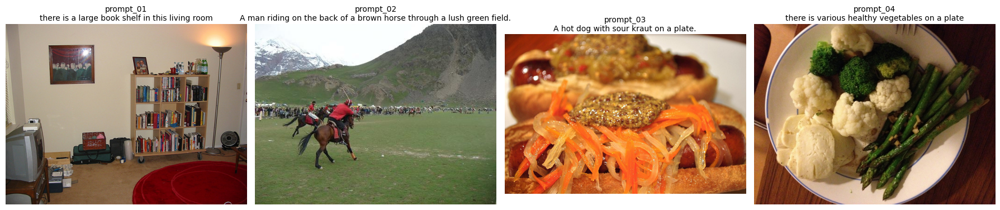

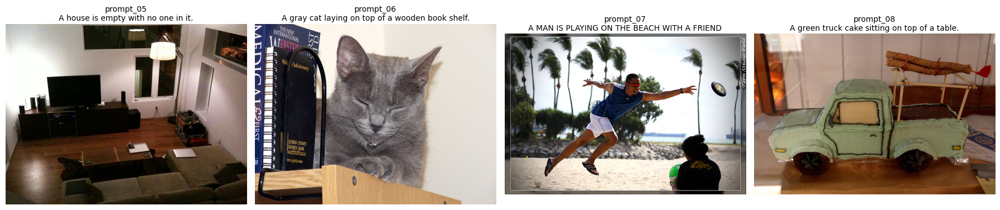

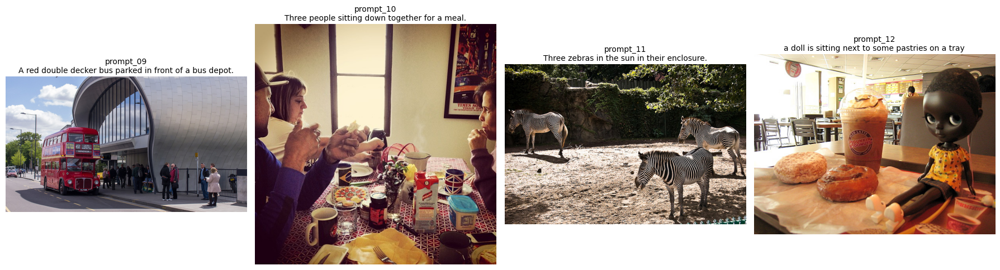

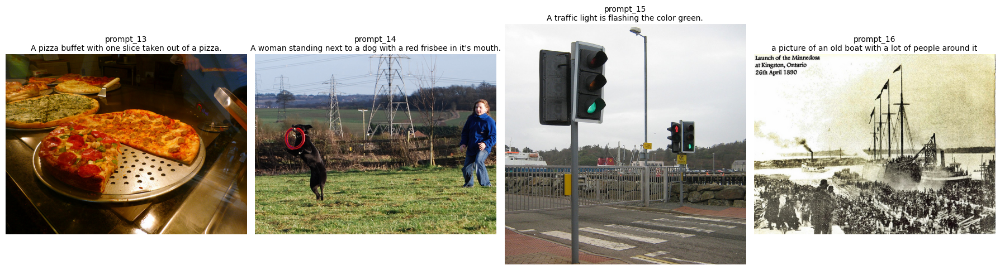

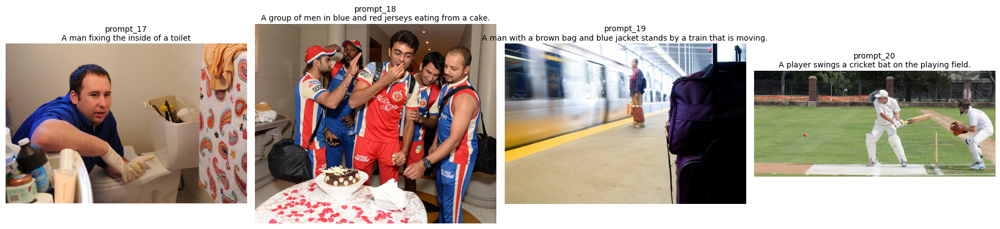

In [2]:
import json
import urllib.request
from pathlib import Path

import matplotlib.pyplot as plt
from PIL import Image

# Load the previously selected prompts
REFERENCE_DIR = DATA_DIR / "reference_images"
REFERENCE_DIR.mkdir(parents=True, exist_ok=True)

prompts_path = DATA_DIR / "baseline_prompts.json"

with open(prompts_path, "r", encoding="utf-8") as f:
    baseline_prompts = json.load(f)

# Download the original COCO images corresponding to each prompt
failed_downloads = []

for item in baseline_prompts:
    filename = item.get("original_file_name")

    if not filename:
        print(f"Missing COCO filename: {item['prompt_id']}")
        failed_downloads.append(item["prompt_id"])
        continue

    image_path = REFERENCE_DIR / filename
    image_url = f"http://images.cocodataset.org/train2017/{filename}"

    try:
        if not image_path.exists():
            request = urllib.request.Request(
                image_url,
                headers={"User-Agent": "Mozilla/5.0"}
            )

            with urllib.request.urlopen(request, timeout=60) as response:
                image_path.write_bytes(response.read())

        # Verify that the downloaded file is a valid image
        with Image.open(image_path) as image:
            image.verify()

        # Store a path relative to the project directory
        item["local_reference_image"] = (
            image_path.relative_to(PROJECT_DIR).as_posix()
        )
        item["reference_source_url"] = image_url

        print(f"Ready: {item['prompt_id']} — {filename}")

    except Exception as error:
        image_path.unlink(missing_ok=True)
        item.pop("local_reference_image", None)
        failed_downloads.append(item["prompt_id"])
        print(f"Failed: {item['prompt_id']} — {error}")

# Save the updated prompt records
with open(prompts_path, "w", encoding="utf-8") as f:
    json.dump(baseline_prompts, f, ensure_ascii=False, indent=2)

print(f"\nReady: {len(baseline_prompts) - len(failed_downloads)}")
print(f"Failed: {len(failed_downloads)}")

# Display reference images in groups of four
ready_items = [
    item for item in baseline_prompts
    if item.get("local_reference_image")
    and (PROJECT_DIR / item["local_reference_image"]).is_file()
]

for start in range(0, len(ready_items), 4):
    batch = ready_items[start:start + 4]
    fig, axes = plt.subplots(1, 4, figsize=(18, 5))

    for ax in axes:
        ax.axis("off")

    for ax, item in zip(axes, batch):
        image_path = PROJECT_DIR / item["local_reference_image"]

        with Image.open(image_path) as image:
            ax.imshow(image.convert("RGB"))

        ax.set_title(
            f"{item['prompt_id']}\n{item['prompt']}",
            fontsize=10,
            wrap=True
        )

    plt.tight_layout()
    plt.show()

***3. Install Generation Dependencies***

The following optional command installs the specified versions of Diffusers, Transformers, Accelerate, and Safetensors. It is commented out because installation has already been completed. For a new environment, remove the leading #, run the command, and restart the kernel before continuing. PyTorch must also be installed.

In [3]:
# %pip install "diffusers==0.36.0" "transformers==4.57.6" "accelerate==1.10.1" "safetensors==0.7.0"

***4. Load Stable Diffusion and Generate the First Image***

Load pretrained Stable Diffusion 1.5 and generate one image from the first saved prompt, without fine-tuning. Use 25 inference steps, guidance scale 7.5, a 512 × 512 resolution, and the recorded seed. Save the image and generation metadata, measure the runtime, and display the result. The code uses CUDA when available and otherwise runs on the CPU.

~/Desktop/P2/Rhea/NU Grad/IE 7615/ie7615-env/lib/python3.9/site-packages/torch/amp/autocast_mode.py:266: UserWarning: User provided device_type of 'cuda', but CUDA is not available. Disabling
  warnings.warn(


Loading model on cpu...


model_index.json:   0%|          | 0.00/541 [00:00<?, ?B/s]

Fetching 15 files:   0%|          | 0/15 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/342 [00:00<?, ?B/s]

config.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

scheduler_config.json:   0%|          | 0.00/308 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/617 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/472 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/806 [00:00<?, ?B/s]

safety_checker/model.safetensors:   0%|          | 0.00/1.22G [00:00<?, ?B/s]

text_encoder/model.safetensors:   0%|          | 0.00/492M [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/547 [00:00<?, ?B/s]

unet/diffusion_pytorch_model.safetensors:   0%|          | 0.00/3.44G [00:00<?, ?B/s]

vae/diffusion_pytorch_model.safetensors:   0%|          | 0.00/335M [00:00<?, ?B/s]

Loading pipeline components...:   0%|          | 0/7 [00:00<?, ?it/s]

`torch_dtype` is deprecated! Use `dtype` instead!



Prompt: there is a large book shelf in this living room
Generating image...


  0%|          | 0/25 [00:00<?, ?it/s]


Saved to: IE7615-Group3-Project2/Milestone 1/Project2_Baseline/outputs/generated/prompt_01.png
Generation time: 5.32 minutes


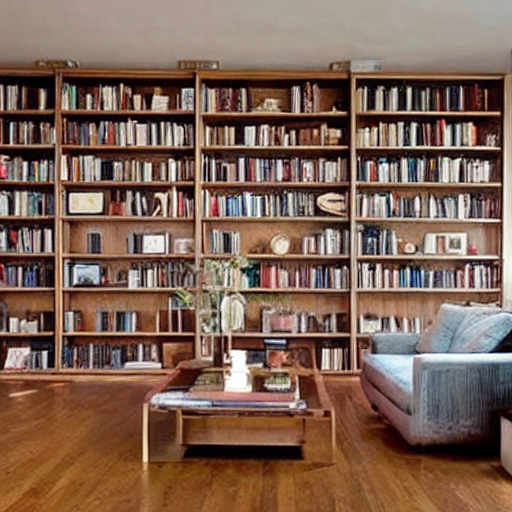

In [4]:
import json
import time
from pathlib import Path

import torch
from diffusers import StableDiffusionPipeline
from IPython.display import display

# Load the saved prompts
PROMPTS_PATH = PROJECT_DIR / "data" / "baseline_prompts.json"
GENERATED_DIR = PROJECT_DIR / "outputs" / "generated"
GENERATED_DIR.mkdir(parents=True, exist_ok=True)

with open(PROMPTS_PATH, "r", encoding="utf-8") as f:
    baseline_prompts = json.load(f)

# Configure the pretrained baseline model
MODEL_ID = "stable-diffusion-v1-5/stable-diffusion-v1-5"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
DTYPE = torch.float16 if DEVICE == "cuda" else torch.float32

print(f"Loading model on {DEVICE}...")

pipe = StableDiffusionPipeline.from_pretrained(
    MODEL_ID,
    torch_dtype=DTYPE,
    use_safetensors=True,
)
pipe = pipe.to(DEVICE)

# Select the first prompt for an initial generation run
item = baseline_prompts[0]

settings = {
    "num_inference_steps": 25,
    "guidance_scale": 7.5,
    "height": 512,
    "width": 512,
}

# Use a fixed seed for reproducibility
generator = torch.Generator(device="cpu").manual_seed(
    item["generation_seed"]
)

print(f"\nPrompt: {item['prompt']}")
print("Generating image...")

start_time = time.perf_counter()

with torch.inference_mode():
    result = pipe(
        prompt=item["prompt"],
        generator=generator,
        **settings,
    )

elapsed_seconds = time.perf_counter() - start_time

# Save the generated image
generated_image = result.images[0]
image_path = GENERATED_DIR / f"{item['prompt_id']}.png"
generated_image.save(image_path)

# Save the generation settings and runtime
metadata = {
    **item,
    "model_id": MODEL_ID,
    "device": DEVICE,
    "dtype": str(DTYPE),
    "settings": settings,
    "scheduler": type(pipe.scheduler).__name__,
    "scheduler_config": dict(pipe.scheduler.config),
    "elapsed_seconds": round(elapsed_seconds, 2),
    "generated_image": image_path.relative_to(PROJECT_DIR).as_posix(),
    "nsfw_content_detected": result.nsfw_content_detected,
}

metadata_path = GENERATED_DIR / f"{item['prompt_id']}.json"

with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(metadata, f, ensure_ascii=False, indent=2, default=str)

print(f"\nSaved to: {image_path}")
print(f"Generation time: {elapsed_seconds / 60:.2f} minutes")

display(generated_image)

***5. Generate the Remaining Baseline Images***

Reuse the loaded pipeline and apply the same settings to the selected prompts, skipping records that already have both an image and metadata file. Save each new output immediately, together with its seed, settings, package versions, runtime, and safety-checker status. Run this cell after the model-loading cell in the same kernel session. A completed output may be a safety-filtered placeholder rather than an assessable image.

In [5]:
import time
import json
import importlib.metadata

# Record package versions for reproducibility
package_versions = {
    name: importlib.metadata.version(name)
    for name in [
        "torch",
        "diffusers",
        "transformers",
        "accelerate",
        "safetensors",
    ]
}

# Use the same generation settings for every prompt
settings = {
    "num_inference_steps": 25,
    "guidance_scale": 7.5,
    "height": 512,
    "width": 512,
}

total_start = time.perf_counter()

for index, item in enumerate(baseline_prompts, start=1):
    image_path = GENERATED_DIR / f"{item['prompt_id']}.png"
    metadata_path = GENERATED_DIR / f"{item['prompt_id']}.json"

    # Skip outputs that were already generated and recorded
    if image_path.exists() and metadata_path.exists():
        print(f"[{index}/20] Skipping completed: {item['prompt_id']}")
        continue

    print(f"\n[{index}/20] Generating: {item['prompt_id']}")
    print(f"Prompt: {item['prompt']}")

    generator = torch.Generator(device="cpu").manual_seed(
        item["generation_seed"]
    )

    start = time.perf_counter()

    with torch.inference_mode():
        result = pipe(
            prompt=item["prompt"],
            generator=generator,
            **settings,
        )

    elapsed = time.perf_counter() - start

    # Save each image immediately so completed work is preserved
    result.images[0].save(image_path)

    metadata = {
        **item,
        "model_id": MODEL_ID,
        "device": DEVICE,
        "dtype": str(DTYPE),
        "settings": settings.copy(),
        "scheduler": type(pipe.scheduler).__name__,
        "scheduler_config": dict(pipe.scheduler.config),
        "package_versions": package_versions,
        "elapsed_seconds": round(elapsed, 2),
        "generated_image": image_path.relative_to(PROJECT_DIR).as_posix(),
        "nsfw_content_detected": result.nsfw_content_detected,
    }

    with open(metadata_path, "w", encoding="utf-8") as f:
        json.dump(metadata, f, ensure_ascii=False, indent=2, default=str)

    print(f"Saved: {image_path.name} | Time: {elapsed / 60:.2f} minutes")

    if result.nsfw_content_detected and any(result.nsfw_content_detected):
        print("Safety checker flagged this output; review it during evaluation.")

# Count completed outputs for the selected prompts
completed = sum(
    (GENERATED_DIR / f"{item['prompt_id']}.png").exists()
    and (GENERATED_DIR / f"{item['prompt_id']}.json").exists()
    for item in baseline_prompts
)

print(f"\nCompleted outputs: {completed}/{len(baseline_prompts)}")
print(f"Elapsed time for this cell: {(time.perf_counter() - total_start) / 60:.2f} minutes")
print(f"Output folder: {GENERATED_DIR}")

[1/20] Skipping completed: prompt_01

[2/20] Generating: prompt_02
Prompt: A man riding on the back of a brown horse through a lush green field.


  0%|          | 0/25 [00:00<?, ?it/s]

Saved: prompt_02.png | Time: 2.36 minutes

[3/20] Generating: prompt_03
Prompt: A hot dog with sour kraut on a plate.


  0%|          | 0/25 [00:00<?, ?it/s]

Saved: prompt_03.png | Time: 2.01 minutes

[4/20] Generating: prompt_04
Prompt: there is various healthy vegetables on a plate


  0%|          | 0/25 [00:00<?, ?it/s]

Saved: prompt_04.png | Time: 1.91 minutes

[5/20] Generating: prompt_05
Prompt: A house is empty with no one in it.


  0%|          | 0/25 [00:00<?, ?it/s]

Saved: prompt_05.png | Time: 4.53 minutes

[6/20] Generating: prompt_06
Prompt: A gray cat laying on top of a wooden book shelf.


  0%|          | 0/25 [00:00<?, ?it/s]

Saved: prompt_06.png | Time: 2.06 minutes

[7/20] Generating: prompt_07
Prompt: A MAN IS PLAYING ON THE BEACH WITH A FRIEND


  0%|          | 0/25 [00:00<?, ?it/s]

Potential NSFW content was detected in one or more images. A black image will be returned instead. Try again with a different prompt and/or seed.


Saved: prompt_07.png | Time: 2.74 minutes
Safety checker flagged this output; review it during evaluation.

[8/20] Generating: prompt_08
Prompt: A green truck cake sitting on top of a table.


  0%|          | 0/25 [00:00<?, ?it/s]

Saved: prompt_08.png | Time: 0.99 minutes

[9/20] Generating: prompt_09
Prompt: A red double decker bus parked in front of a bus depot.


  0%|          | 0/25 [00:00<?, ?it/s]

Saved: prompt_09.png | Time: 1.13 minutes

[10/20] Generating: prompt_10
Prompt: Three people sitting down together for a meal.


  0%|          | 0/25 [00:00<?, ?it/s]

Saved: prompt_10.png | Time: 1.15 minutes

[11/20] Generating: prompt_11
Prompt: Three zebras in the sun in their enclosure.


  0%|          | 0/25 [00:00<?, ?it/s]

Saved: prompt_11.png | Time: 1.91 minutes

[12/20] Generating: prompt_12
Prompt: a doll is sitting next to some pastries on a tray


  0%|          | 0/25 [00:00<?, ?it/s]

Saved: prompt_12.png | Time: 1.98 minutes

[13/20] Generating: prompt_13
Prompt: A pizza buffet with one slice taken out of a pizza.


  0%|          | 0/25 [00:00<?, ?it/s]

Saved: prompt_13.png | Time: 1.71 minutes

[14/20] Generating: prompt_14
Prompt: A woman standing next to a dog with a red frisbee in it's mouth.


  0%|          | 0/25 [00:00<?, ?it/s]

Saved: prompt_14.png | Time: 2.44 minutes

[15/20] Generating: prompt_15
Prompt: A traffic light is flashing the color green.


  0%|          | 0/25 [00:00<?, ?it/s]

Saved: prompt_15.png | Time: 1.69 minutes

[16/20] Generating: prompt_16
Prompt: a picture of an old boat with a lot of people around it


  0%|          | 0/25 [00:00<?, ?it/s]

Saved: prompt_16.png | Time: 1.86 minutes

[17/20] Generating: prompt_17
Prompt: A man fixing the inside of a toilet


  0%|          | 0/25 [00:00<?, ?it/s]

Saved: prompt_17.png | Time: 1.76 minutes

[18/20] Generating: prompt_18
Prompt: A group of men in blue and red jerseys eating from a cake.


  0%|          | 0/25 [00:00<?, ?it/s]

Saved: prompt_18.png | Time: 1.75 minutes

[19/20] Generating: prompt_19
Prompt: A man with a brown bag and blue jacket stands by a train that is moving.


  0%|          | 0/25 [00:00<?, ?it/s]

Saved: prompt_19.png | Time: 1.59 minutes

[20/20] Generating: prompt_20
Prompt: A player swings a cricket bat on the playing field.


  0%|          | 0/25 [00:00<?, ?it/s]

Saved: prompt_20.png | Time: 1.65 minutes

Completed outputs: 20/20
Elapsed time for this cell: 37.22 minutes
Output folder: IE7615-Group3-Project2/Milestone 1/Project2_Baseline/outputs/generated


***6. Compare Reference and Generated Images***

Display each original COCO reference beside its generated output and save the comparison as a PNG. Label safety-checker flags separately. Evaluate whether the generated image captures the caption’s objects, attributes, and relationships, while noting visual artifacts; matching the reference photograph exactly is not required.

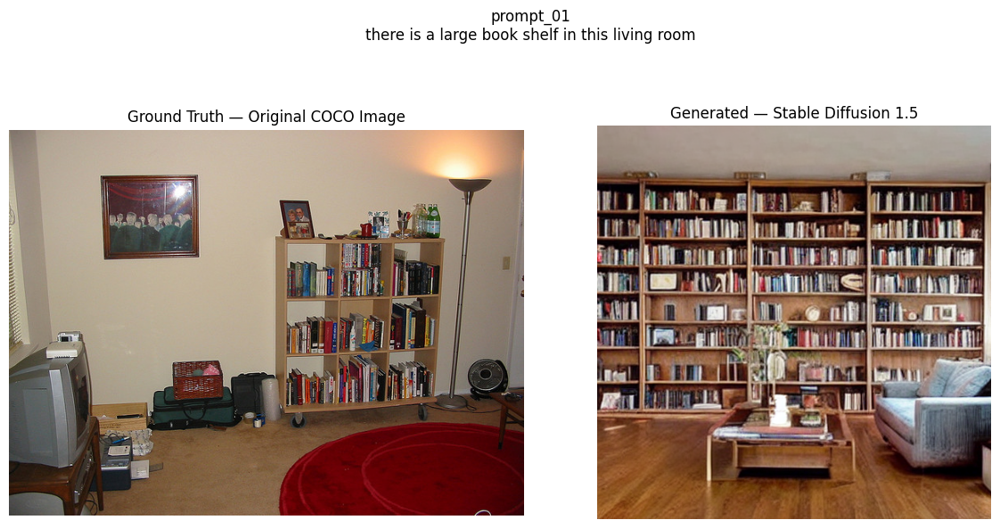

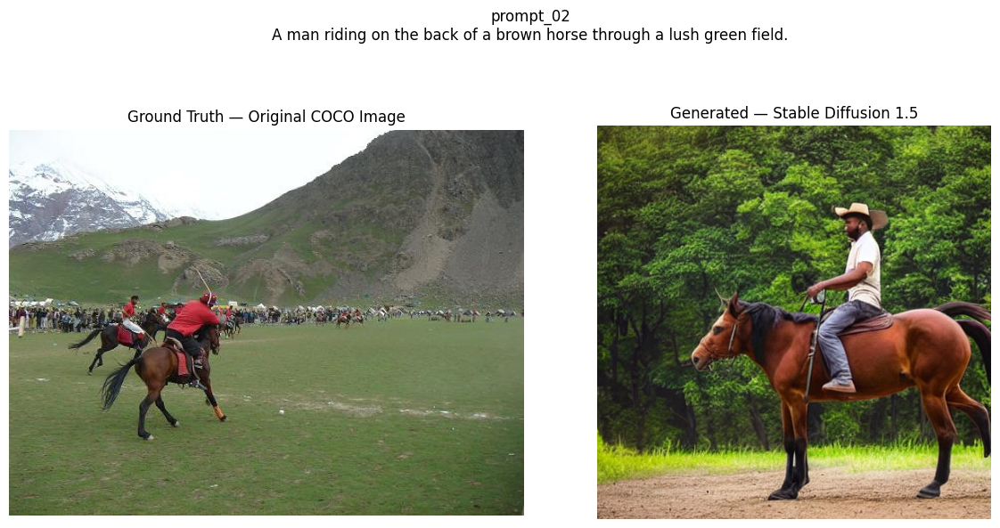

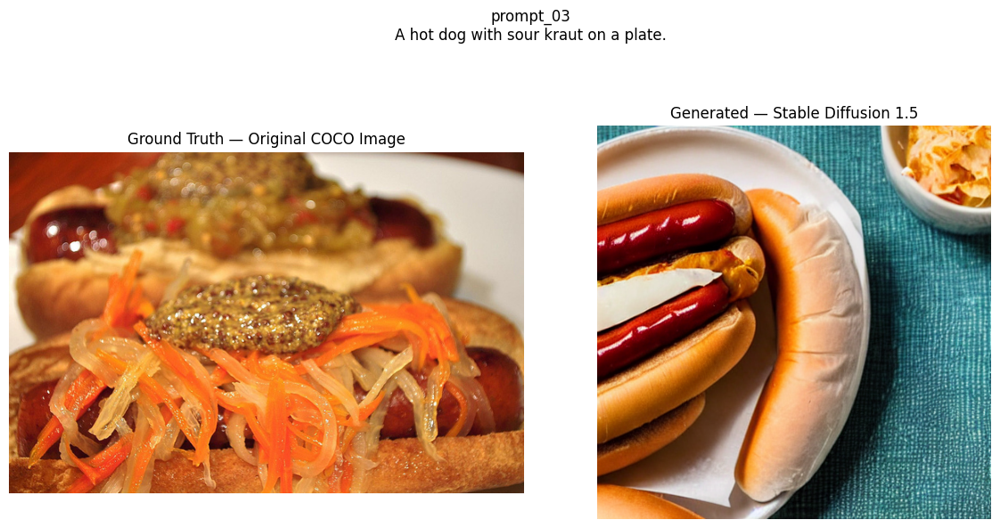

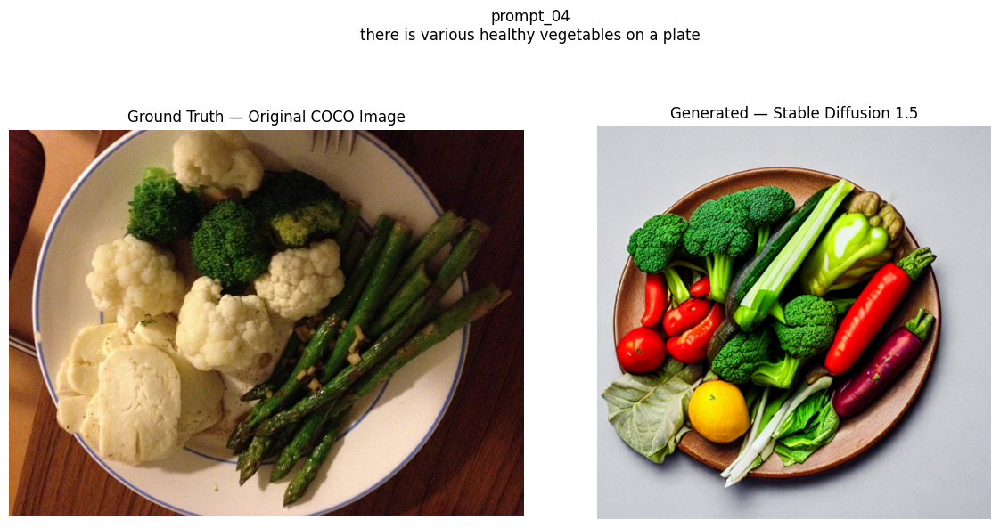

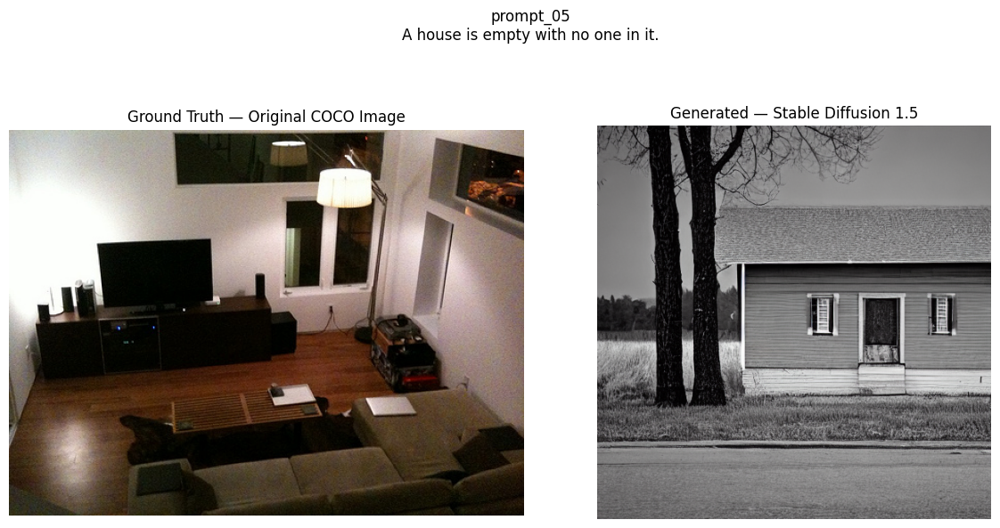

...

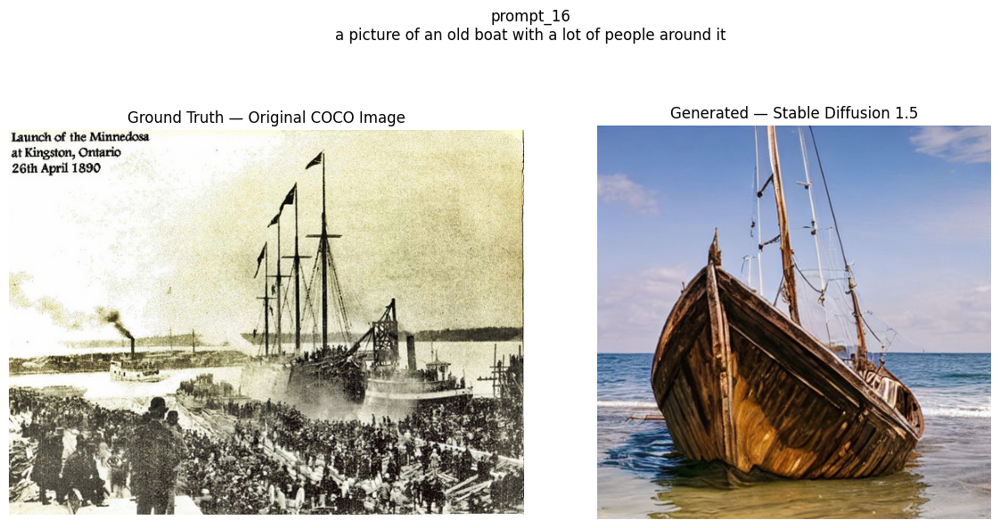

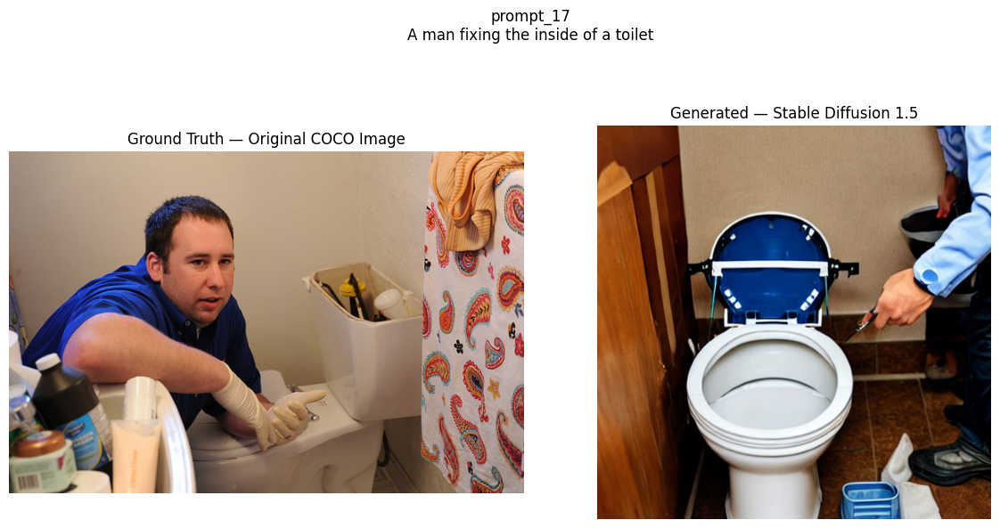

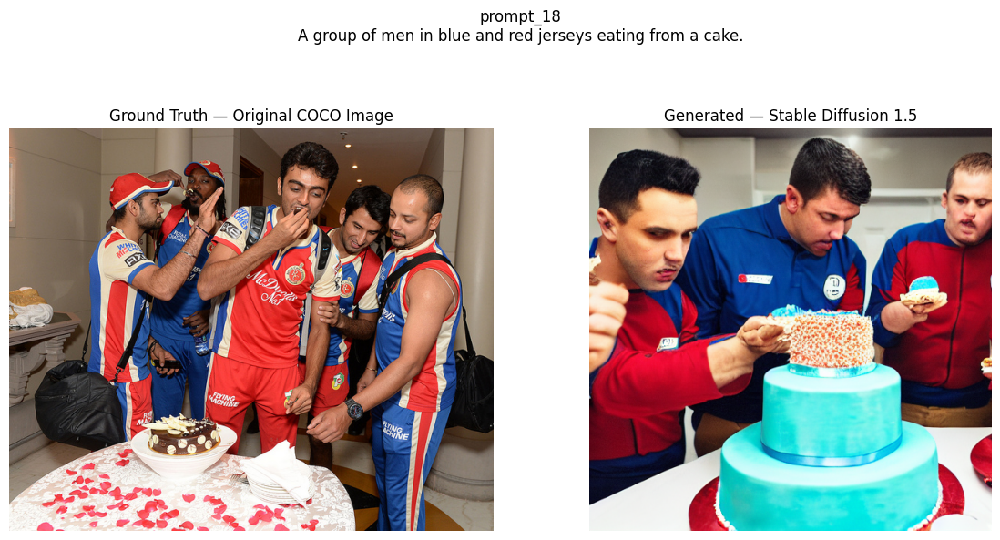

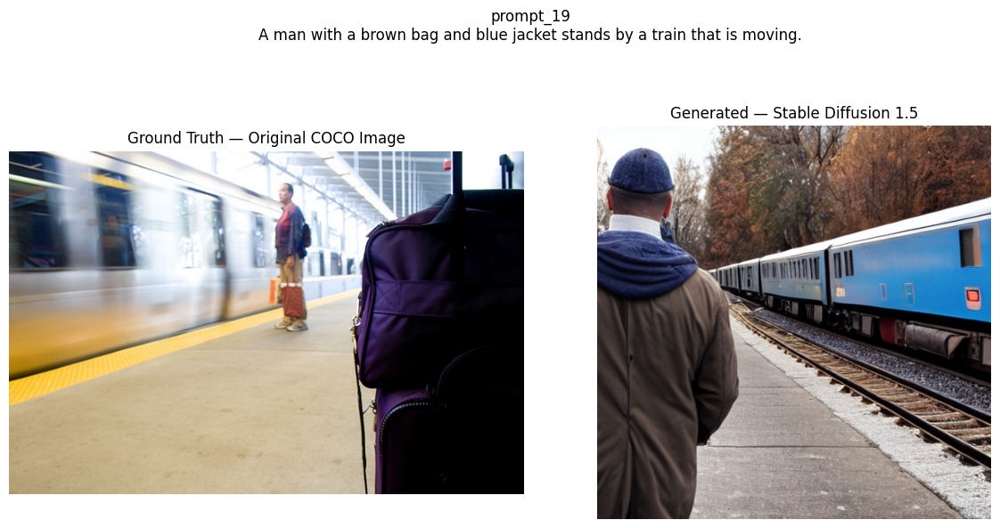

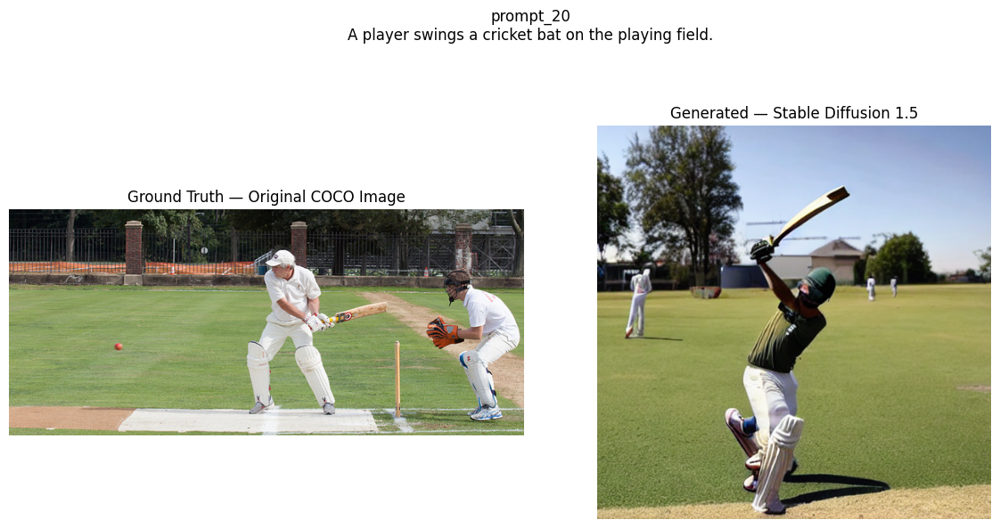


Saved comparisons: 20/20
Comparison folder: IE7615-Group3-Project2/Milestone 1/Project2_Baseline/outputs/comparisons


In [6]:
import json
import textwrap
from pathlib import Path

import matplotlib.pyplot as plt
from PIL import Image

# Set up paths
COMPARISON_DIR = PROJECT_DIR / "outputs" / "comparisons"
COMPARISON_DIR.mkdir(parents=True, exist_ok=True)

# Load the selected prompts
with open(
    PROJECT_DIR / "data" / "baseline_prompts.json",
    "r",
    encoding="utf-8",
) as f:
    baseline_prompts = json.load(f)

saved_count = 0

for item in baseline_prompts:
    reference_path = PROJECT_DIR / item["local_reference_image"]
    generated_path = GENERATED_DIR / f"{item['prompt_id']}.png"
    metadata_path = GENERATED_DIR / f"{item['prompt_id']}.json"

    if not reference_path.exists() or not generated_path.exists():
        print(f"Missing image file: {item['prompt_id']}")
        continue

    # Read the safety-checker status, if available
    flagged = False
    if metadata_path.exists():
        with open(metadata_path, "r", encoding="utf-8") as f:
            metadata = json.load(f)
        flagged = any(metadata.get("nsfw_content_detected") or [])

    # Load images without cropping or stretching them
    with Image.open(reference_path) as image:
        reference_image = image.convert("RGB")

    with Image.open(generated_path) as image:
        generated_image = image.convert("RGB")

    # Create a side-by-side comparison
    fig, axes = plt.subplots(1, 2, figsize=(12, 6))

    axes[0].imshow(reference_image)
    axes[0].set_title("Ground Truth — Original COCO Image")

    axes[1].imshow(generated_image)
    axes[1].set_title(
        "Generated — Safety Checker Flagged"
        if flagged
        else "Generated — Stable Diffusion 1.5"
    )

    for ax in axes:
        ax.axis("off")

    title = (
        f"{item['prompt_id']}\n"
        + textwrap.fill(item["prompt"], width=95)
    )
    fig.suptitle(title, fontsize=12)
    fig.tight_layout(rect=[0, 0, 1, 0.88])

    # Save the comparison for the report and repository
    comparison_path = COMPARISON_DIR / f"{item['prompt_id']}_comparison.png"
    fig.savefig(comparison_path, dpi=150, bbox_inches="tight")

    plt.show()
    plt.close(fig)
    saved_count += 1

print(f"\nSaved comparisons: {saved_count}/{len(baseline_prompts)}")
print(f"Comparison folder: {COMPARISON_DIR}")

**Baseline Prompt-to-Image Generation: Qualitative Memo**

We evaluated pretrained Stable Diffusion 1.5 using 20 captions sampled from our curated COCO subset with selection seed 42. Each caption was used without additional prompt engineering. Generation used 25 inference steps, a guidance scale of 7.5, a resolution of 512 × 512, and a recorded seed for each prompt. No fine-tuning was performed. Outputs were compared against the corresponding original COCO images, rather than the dataset pipeline’s center-cropped exports. Assessment focused on caption alignment and visual coherence, not exact reconstruction of the reference photograph.

Several outputs captured the requested concepts effectively. Prompt 01 generated a living room with a large bookshelf, while prompt 04 produced a plate containing varied vegetables. Prompt 08 successfully combined color, shape, and object type into a green truck-shaped cake on a table. Prompt 10 depicted exactly three people seated together for a meal, although facial and hand details contained artifacts. These examples demonstrate that a pretrained model can generate recognizable scenes from dataset captions without task-specific training.

More detailed requirements were less reliable. Prompt 09 generated a red bus, but it did not clearly depict two passenger decks. Prompt 13 produced a pizza without the requested missing slice or an evident buffet setting. Prompt 14 included a woman and a dog but omitted the red frisbee in the dog’s mouth. Prompt 16 generated an old-looking boat while omitting the requested crowd. In prompt 19, the brown bag was not visible, and the jacket was predominantly brown-gray rather than blue. These failures illustrate the difference between capturing a scene’s general subject and satisfying all its attributes and relationships.

Visual plausibility was also inconsistent. The horse in prompt 02 had distorted legs, and the cricket scene in prompt 20 contained an unusually shaped bat and awkward limb geometry. Prompt 15 emphasized green illumination but produced an implausible traffic-signal arrangement. Flashing cannot be established from a single still image. Conversely, the exterior house in prompt 05 should not automatically be considered incorrect merely because the reference shows an interior: the caption does not specify viewpoint.

The experiment demonstrates **conditional sampling**: text guides generation from seeded noise, but does not uniquely determine a photograph. Stable Diffusion performs denoising within a compressed **latent representation**, which is subsequently decoded into image pixels. Our task therefore uses a **generative** framing-creating new images-rather than a **discriminative** framing, such as classifying an existing image or ranking image-caption matches.

Twenty generation attempts completed, but prompt 07 was flagged by the safety checker and returned a black placeholder, leaving 19 visible outputs for qualitative assessment. This filtering event was recorded separately from visual-quality failures; the placeholder does not establish whether filtering was justified.

Although outputs varied across subjects, this experiment cannot establish or rule out **mode collapse risk**. One sample per prompt provides insufficient evidence about within-prompt diversity. Multiple seeds per caption would support a stronger investigation. Overall, the baseline establishes a reproducible starting point and identifies attribute binding, object relationships, and anatomical consistency as priorities for subsequent evaluation.